# Sample4Geo: retrain on CVIAN left/right photos

The model you have now was trained on **360° panoramas**, so ordinary photos lose accuracy.
This notebook retrains it on your converted CVIAN dataset, where each panorama has been split into a
**left** and a **right** ordinary photo. Each photo is trained against the satellite image of its location.

**What it does**
1. Copies your left/right photos and the CVIAN satellite images onto the Colab disk.
2. Pairs every photo with its satellite image by CVIAN location number and checks nothing is missing.
3. Holds out **subarea 5**, the same area your earlier run was tested on, so before and after results are directly comparable.
4. Tests the starting model on the held-out photos (**before** score), then retrains it and tests again after every epoch.
5. Saves everything to Google Drive after every epoch. If Colab disconnects, run all cells again and it carries on where it stopped.

**Before you start**
* *Runtime → Change runtime type →* pick a **GPU** (A100 or L4 if you have them; T4 works but is slower).
* Put your converted dataset on Google Drive (as a folder or a .zip) and set its path in Step 2.
* Then *Runtime → Run all*.

**How the photos and satellite images are prepared for training**
* A photo's compass direction is unknown, so during training the satellite image is randomly turned (90°, 180° or 270°).
  This teaches the model to match a photo whichever way it was taken.
* The left and right photos of one place share a satellite image. They are both used in every epoch, but never in the same batch,
  because the model learns by telling the right satellite image apart from the others in its batch.
* Photos are randomly cropped and zoomed a little and have their colours varied, so the model copes with phone photos that are framed differently.

## Step 1 – Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, subprocess
def sh(cmd):
    """Run a shell command and show its output in the notebook."""
    try:
        get_ipython().system(cmd)
    except NameError:
        subprocess.run(cmd, shell=True, check=False)

sh('nvidia-smi --query-gpu=name,memory.total --format=csv,noheader || echo "NO GPU - Runtime > Change runtime type > GPU"')
sh("pip install -q timm geopandas gdown")
if not os.path.exists("/content/CVDisaster"):
    sh("git clone -q https://github.com/tum-bgd/CVDisaster.git /content/CVDisaster")
print("Setup done")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB
Setup done


## Step 2 – Settings
Edit the paths here. The other settings can usually stay as they are.

In [ ]:
# ======================= SETTINGS (edit these) =======================
# Your converted dataset of left/right photos: a folder or a .zip on Google Drive (a .zip copies much faster).
# Inside: 0_minordamage / 1_moderatedamage / 2_severedamage folders (at any depth), with the
# CVIAN location number and L/R (or left/right) in each file name, e.g. 1234_L.png or 1234_right.jpg
PERSPECTIVE_SOURCE = "/content/drive/MyDrive/CVIAN_perspective.zip"

# The original CVIAN dataset supplies the satellite images and the positions used for the subarea split.
# "download" fetches it from TUM (2.1 GB, about 5 minutes). Or give the path of m1749324.zip or a CVIAN folder on Drive.
# Skipped automatically if your converted dataset already contains the satellite folder and CVIAN_position.geojson.
CVIAN_SOURCE = "download"

# Model to start from:
#   "cvian_panorama" = your earlier CVIAN fine-tuned model (newest weights_end.pth under PANORAMA_RUNS)
#   "cvusa"          = the original Sample4Geo CVUSA weights (the same start as Experiment 2; downloaded if missing)
#   or the path of any .pth file
START_FROM    = "cvian_panorama"
PANORAMA_RUNS = "/content/drive/MyDrive/cvdisaster/convnext_base.fb_in22k_ft_in1k_384"
CVUSA_WEIGHTS = "/content/sample4geo_pretrained/pretrained/cvusa/convnext_base.fb_in22k_ft_in1k_384/weights_e40_98.6830.pth"

# Results and checkpoints are saved here (on Drive, so they survive a disconnect)
OUT_ROOT = "/content/drive/MyDrive/cvdisaster_perspective"
RUN_NAME = "run1"     # same name = carry on after a disconnect; new name = a new experiment

# Training
SPLIT          = "subarea5"  # "subarea5" = same held-out area as your earlier run (keep for a fair comparison); "random" = 80/20
EPOCHS         = 10          # 10 matches your earlier Sample4Geo and TransGeo runs
BATCH_SIZE     = None        # None = chosen from GPU memory (T4: 8, L4: 16, A100: 32)
LR             = None        # None = same learning rate per image as the original CVDisaster training (0.001 per 128)
HARD_NEGATIVES = True        # Sample4Geo's similarity sampling: batches include look-alike places (slower, usually better)
GROUND_WIDTH   = 384         # photos are resized to this width; the height follows the shape of your photos
SEED           = 42
# =====================================================================

## Step 3 – Copy the data onto the Colab disk
Training straight from Google Drive is very slow, so everything is copied to the Colab disk first. This is skipped if it is already there.

In [ ]:
import glob, shutil, zipfile

DATA = "/content/data"
IMG_EXTS = (".png", ".jpg", ".jpeg", ".webp", ".bmp", ".tif", ".tiff")
os.makedirs(DATA, exist_ok=True)

def has_images(folder):
    return any(f.lower().endswith(IMG_EXTS) for _, _, fs in os.walk(folder) for f in fs)

def unpack(src, dest, only=()):
    """Copy a folder, or unzip a .zip, from Drive to the Colab disk (skipped if already there)."""
    if os.path.isdir(dest) and os.listdir(dest):
        print(f"Already on the Colab disk: {dest}")
        return dest
    os.makedirs(dest, exist_ok=True)
    if src.lower().endswith(".zip"):
        print(f"Unzipping {src} ...")
        patterns = " ".join(f"'*{p}/*'" for p in only)
        sh(f"unzip -q -o '{src}' {patterns} -d '{dest}'")
    else:
        print(f"Copying {src} ...")
        shutil.copytree(src, dest, dirs_exist_ok=True)
    return dest

def find_sat_dirs(root):
    """Folders whose name contains 'sat' and that hold images (not looking inside one once found)."""
    found = []
    for d, subdirs, _ in os.walk(root):
        subdirs.sort()
        if "sat" in os.path.basename(d).lower() and has_images(d):
            found.append(d)
            subdirs.clear()
    return found

def find_file(root, name):
    hits = sorted(glob.glob(f"{root}/**/{name}", recursive=True))
    return hits[0] if hits else None

# 1) your left/right photos
assert os.path.exists(PERSPECTIVE_SOURCE), f"Not found: {PERSPECTIVE_SOURCE} - set PERSPECTIVE_SOURCE in Step 2"
PERSP_ROOT = unpack(PERSPECTIVE_SOURCE, f"{DATA}/perspective")

# 2) satellite images and positions: from your dataset if it has them, otherwise from the original CVIAN
SAT_DIRS = find_sat_dirs(PERSP_ROOT)
POS_FILE = find_file(PERSP_ROOT, "CVIAN_position.geojson")
if not SAT_DIRS or (SPLIT == "subarea5" and POS_FILE is None):
    CVIAN_ROOT = f"{DATA}/cvian"
    if CVIAN_SOURCE == "download":
        zip_path = f"{DATA}/m1749324.zip"
        if not (os.path.isdir(CVIAN_ROOT) and find_sat_dirs(CVIAN_ROOT)):
            shutil.rmtree(CVIAN_ROOT, ignore_errors=True)          # clear any half-finished earlier attempt
            for attempt in range(1, 4):
                if os.path.exists(zip_path) and zipfile.is_zipfile(zip_path):
                    break
                if os.path.exists(zip_path):
                    print(f"The downloaded file is broken ({os.path.getsize(zip_path) / 2**30:.2f} GB) - downloading again")
                    os.remove(zip_path)
                print(f"Downloading CVIAN (2.1 GB), attempt {attempt} of 3 ...")
                sh(f'wget --progress=dot:giga --tries=3 "https://dataserv.ub.tum.de/index.php/s/m1749324/download" -O {zip_path}')
            assert os.path.exists(zip_path) and zipfile.is_zipfile(zip_path), (
                "Could not download CVIAN from TUM (the server may be busy). Try again later, or download "
                "https://dataserv.ub.tum.de/index.php/s/m1749324/download yourself, put the zip on Drive and "
                "set CVIAN_SOURCE to its path.")
        unpack(zip_path, CVIAN_ROOT, only=("01_Satellite", "02_Position"))
    elif CVIAN_SOURCE.lower().endswith(".zip"):
        unpack(CVIAN_SOURCE, CVIAN_ROOT, only=("01_Satellite", "02_Position"))
    else:   # a CVIAN folder on Drive: copy only the satellite images and positions
        if not (os.path.isdir(CVIAN_ROOT) and os.listdir(CVIAN_ROOT)):
            print(f"Copying satellite images and positions from {CVIAN_SOURCE} ...")
            for d in find_sat_dirs(CVIAN_SOURCE):
                shutil.copytree(d, f"{CVIAN_ROOT}/{os.path.relpath(d, CVIAN_SOURCE)}", dirs_exist_ok=True)
            pos = find_file(CVIAN_SOURCE, "CVIAN_position.geojson")
            shutil.copytree(os.path.dirname(pos), f"{CVIAN_ROOT}/02_Position", dirs_exist_ok=True)
    SAT_DIRS = SAT_DIRS or find_sat_dirs(CVIAN_ROOT)
    POS_FILE = POS_FILE or find_file(CVIAN_ROOT, "CVIAN_position.geojson")

assert SAT_DIRS, "Could not find the satellite images - check CVIAN_SOURCE"
assert POS_FILE or SPLIT != "subarea5", "Could not find CVIAN_position.geojson - check CVIAN_SOURCE, or set SPLIT = 'random'"
print("\nPhotos:          ", PERSP_ROOT)
print("Satellite images:", ", ".join(SAT_DIRS))
print("Positions:       ", POS_FILE)

Already on the Colab disk: /content/data/perspective
Already on the Colab disk: /content/data/cvian

Photos:           /content/data/perspective
Satellite images: /content/data/cvian/m1749324/CVIAN/01_Satellite
Positions:        /content/data/cvian/m1749324/CVIAN/02_Position/CVIAN_position.geojson


## Step 4 – Pair every photo with its satellite image
Check the summary: nearly every photo should be matched, and the example rows should show the same place.

Images found: 8244   satellite images: 4121

LEFT OUT 2 image(s): no CVIAN location number with a satellite image in the name. Examples:
    00_SVI/0_MinorDamage/left_half.png
    00_SVI/0_MinorDamage/right_half.png

Locations: 4121  (4121 with both photos, 0 with only one)
Photos used: 8242  (L: 4121, R: 4121)
By damage class: {'severe damage': 1176, 'moderate damage': 1538, 'minor damage': 1407}

Typical photo shape (height/width): 0.80 -> photos are trained at 384x320 (w x h)


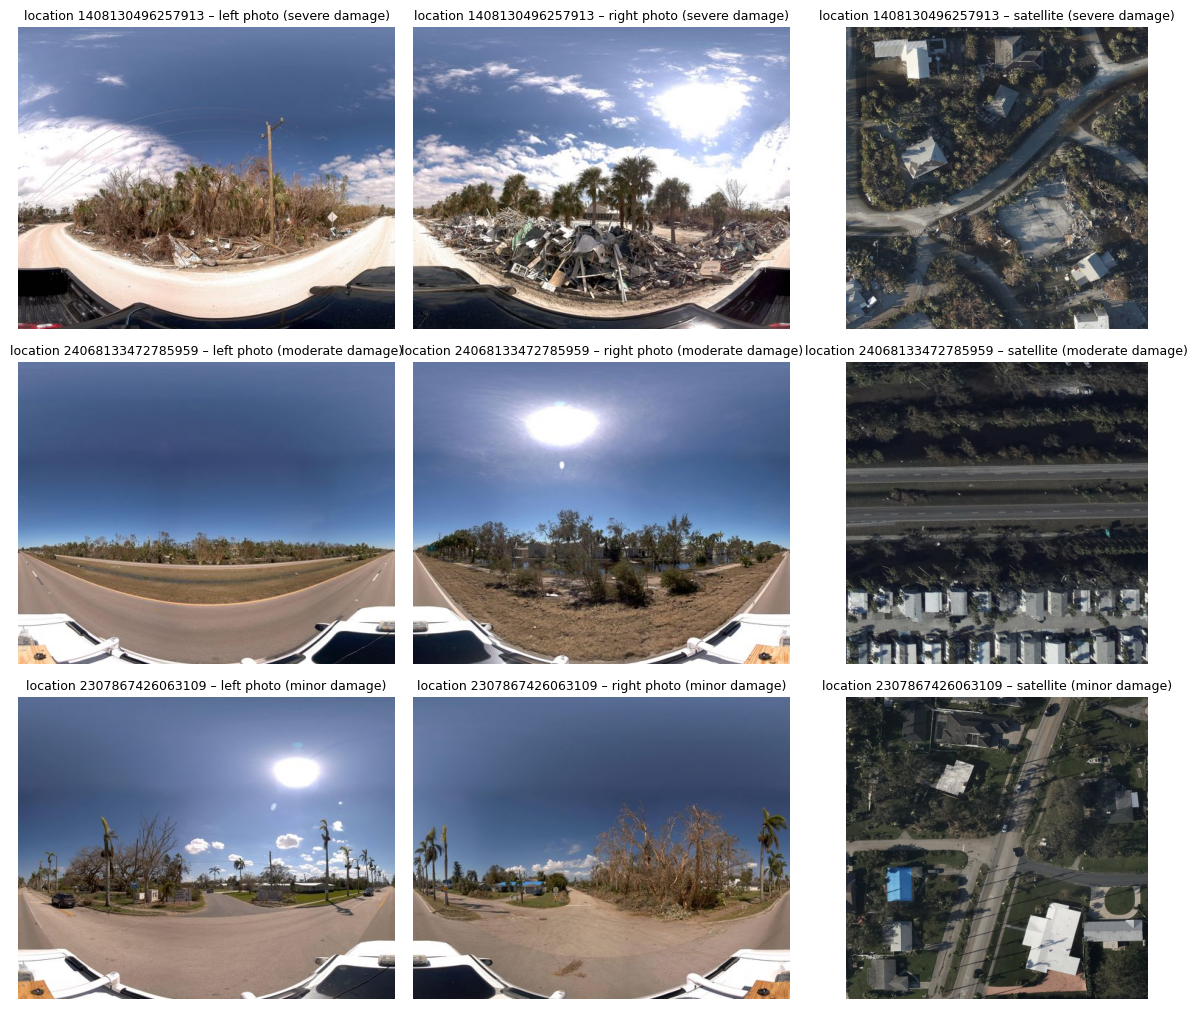

In [ ]:
import re, random
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image

CATEGORY_NAMES = {0: "minor damage", 1: "moderate damage", 2: "severe damage"}

def list_images(root, exclude=()):
    skip = [os.path.abspath(e) + os.sep for e in exclude]
    out = []
    for d, _, files in os.walk(root):
        if any((os.path.abspath(d) + os.sep).startswith(e) for e in skip):
            continue
        out += [Path(d) / f for f in files if f.lower().endswith(IMG_EXTS) and not f.startswith(".")]
    return sorted(out)

def category_of(path):
    """0, 1 or 2 from a folder such as 0_minordamage or 2_SevereDamage."""
    for part in reversed(Path(path).parts[:-1]):
        m = re.match(r"^([012])[_\-\s]", part)
        if m:
            return int(m.group(1))
    return None

SIDE_RE = re.compile(r"(?:^|[_\-\s.\d])(left|right|l|r)(?=$|[_\-\s.\d])", re.I)
def side_of(path):
    """'L' or 'R' from the file name (…_L, …_left, …-R) or from a left/right folder."""
    hits = SIDE_RE.findall(Path(path).stem)
    if hits:
        return "L" if hits[-1].lower().startswith("l") else "R"
    for part in reversed(Path(path).parts[:-1]):
        if part.lower() in ("l", "left"):
            return "L"
        if part.lower() in ("r", "right"):
            return "R"
    return None

# satellite images: CVIAN names them <location number>.png
sat_by_id = {}
for p in [p for d in SAT_DIRS for p in list_images(d)]:
    nums = re.findall(r"\d+", p.stem)
    if nums:
        sat_by_id.setdefault(int(nums[-1]), p)

def id_of(path):
    """The number in the file name that is a CVIAN location with a satellite image."""
    nums = [n for n in re.findall(r"\d+", Path(path).stem) if int(n) in sat_by_id]
    return int(max(nums, key=len)) if nums else None

photo_files = list_images(PERSP_ROOT, exclude=SAT_DIRS)
# CVIAN location numbers have up to 16 digits: keep them as exact integers (Int64), never as decimals
views = pd.DataFrame({"path": [str(p) for p in photo_files],
                      "side": [side_of(p) for p in photo_files],
                      "id": pd.array([id_of(p) for p in photo_files], dtype="Int64"),
                      "category": pd.array([category_of(p) for p in photo_files], dtype="Int64")})
assert len(views), f"No photos found in {PERSP_ROOT}"
print(f"Images found: {len(views)}   satellite images: {len(sat_by_id)}")

def report_drop(mask, why):
    global views
    if mask.any():
        print(f"\nLEFT OUT {mask.sum()} image(s): {why}. Examples:")
        for p in views.loc[mask, "path"].head(5):
            print("   ", os.path.relpath(p, PERSP_ROOT))
        views = views[~mask]

report_drop(views.side.isna(), "no L/R or left/right in the name (e.g. an original panorama)")
report_drop(views.id.isna(), "no CVIAN location number with a satellite image in the name")
report_drop(views.duplicated(["id", "side"]), "a second photo for the same location and side")
views["id"] = views.id.astype("int64")
views["category"] = pd.array([c if c == c and c is not None else category_of(sat_by_id[i])
                              for c, i in zip(views.category, views.id)], dtype="Int64")

locs = (views.pivot(index="id", columns="side", values="path")
             .reindex(columns=["L", "R"]).reset_index())
locs["sat"] = locs.id.map(lambda i: str(sat_by_id[i]))
locs["category"] = locs.id.map(views.groupby("id").category.first())
both = locs.L.notna() & locs.R.notna()
print(f"\nLocations: {len(locs)}  ({both.sum()} with both photos, {(~both).sum()} with only one)")
print(f"Photos used: {len(views)}  (L: {(views.side == 'L').sum()}, R: {(views.side == 'R').sum()})")
print("By damage class:", {CATEGORY_NAMES.get(c, c): n for c, n in Counter(locs.category).items()})
assert len(locs) >= 50, "Too few matched locations - check the file names against the examples above"

# photo shape -> training size
sample = random.Random(0).sample(list(views.path), min(200, len(views)))
aspect = float(np.median([h / w for w, h in (Image.open(p).size for p in sample)]))
GROUND_SIZE = (max(64, int(round(GROUND_WIDTH * aspect / 32)) * 32), GROUND_WIDTH)
print(f"\nTypical photo shape (height/width): {aspect:.2f} -> photos are trained at {GROUND_SIZE[1]}x{GROUND_SIZE[0]} (w x h)")

# a few examples to check by eye
ex = locs[both].sample(min(3, int(both.sum())), random_state=1)
fig, axes = plt.subplots(len(ex), 3, figsize=(12, 3.4 * len(ex)), squeeze=False)
for row, r in zip(axes, ex.itertuples()):
    for ax, p, t in zip(row, (r.L, r.R, r.sat), ("left photo", "right photo", "satellite")):
        ax.imshow(Image.open(p).convert("RGB")); ax.axis("off")
        ax.set_title(f"location {r.id} – {t} ({CATEGORY_NAMES.get(r.category, '?')})", fontsize=9)
plt.tight_layout(); plt.show()

## Step 5 – Split into training and test locations
With `subarea5`, the test locations are the ones in subarea 5, the same as your earlier panorama run.
Both photos of a location always go to the same side of the split. Keep this split when starting from your panorama model:
that model never saw subarea 5, so the test stays fair.

In [ ]:
import json
if SPLIT == "subarea5":
    import geopandas as gpd
    from shapely.geometry import shape
    with open(POS_FILE) as f:          # read the ids as text so long numbers stay exact
        feats = [ft for ft in json.load(f)["features"] if ft.get("geometry")]
    pos = gpd.GeoDataFrame({"id": [str(ft["properties"]["id"]).split(".")[0] for ft in feats]},
                           geometry=[shape(ft["geometry"]) for ft in feats], crs="EPSG:4326")
    areas = pd.concat([gpd.read_file(f"/content/CVDisaster/geolocalization/subarea_{i}.geojson").assign(subarea=i)
                       for i in range(1, 6)], ignore_index=True)
    areas = areas.set_crs(epsg=4326) if areas.crs is None else areas.to_crs(epsg=4326)
    joined = gpd.sjoin(pos, areas[["subarea", "geometry"]], how="left", predicate="within")
    joined = joined.drop_duplicates(subset="id")
    area_of = {int(i): a for i, a in zip(joined["id"], joined["subarea"])}
    locs["subarea"] = locs.id.map(area_of)
    if locs.subarea.isna().all():
        raise ValueError("No location fell inside a subarea - check that CVIAN_position.geojson matches the photos")
    locs["split"] = np.where(locs.subarea == 5, "test", "train")
else:
    rng = np.random.RandomState(SEED)
    locs["split"] = "train"
    for c, grp in locs.groupby("category"):
        test_ids = rng.choice(grp.index, size=int(round(0.2 * len(grp))), replace=False)
        locs.loc[test_ids, "split"] = "test"

train_locs = locs[locs.split == "train"].reset_index(drop=True)
test_locs  = locs[locs.split == "test"].reset_index(drop=True)
summary = locs.assign(photos=locs.L.notna().astype(int) + locs.R.notna().astype(int),
                      damage=locs.category.map(CATEGORY_NAMES))
print(summary.pivot_table(index="damage", columns="split", values="photos", aggfunc=["count", "sum"])
             .rename(columns={"count": "locations", "sum": "photos"}))
print(f"\nTraining: {len(train_locs)} locations   Test: {len(test_locs)} locations")

                locations       photos      
split                test train   test train
damage                                      
minor damage          164  1243    328  2486
moderate damage        71  1467    142  2934
severe damage          32  1144     64  2288

Training: 3854 locations   Test: 267 locations


## Step 6 – Model and training set-up
This loads the starting model and sets up how images are prepared. There is nothing to edit here.

In [ ]:
import sys, time, math, json
import torch, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

sys.path.insert(0, "/content/CVDisaster/geolocalization")
from sample4geo.model import TimmModel

MODEL_NAME = "convnext_base.fb_in22k_ft_in1k_384"
SAT_SIZE = 384
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = min(4, os.cpu_count() or 1)
cv2.setNumThreads(0)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if BATCH_SIZE is None:
    mem_gb = torch.cuda.get_device_properties(0).total_memory / 2**30 if device.type == "cuda" else 0
    BATCH_SIZE = 32 if mem_gb >= 38 else 16 if mem_gb >= 20 else 8
if LR is None:
    LR = 0.001 * BATCH_SIZE / 128
print(f"Device: {device} | batch size {BATCH_SIZE} | learning rate {LR:.2e}")

# ---------------- starting weights ----------------
def resolve_start():
    if START_FROM == "cvian_panorama":
        found = sorted(glob.glob(f"{PANORAMA_RUNS}/*/weights_end.pth"), key=os.path.getmtime)
        assert found, f"No weights_end.pth under {PANORAMA_RUNS} - set PANORAMA_RUNS or START_FROM"
        return found[-1]
    if START_FROM == "cvusa":
        if not os.path.exists(CVUSA_WEIGHTS):
            sh('gdown -q --folder "https://drive.google.com/drive/folders/1PMuUqvDnCb216D8_ZDDJzDD3FxeH5BoA" -O /content/sample4geo_pretrained')
            sh("unzip -q -o /content/sample4geo_pretrained/pretrained.zip -d /content/sample4geo_pretrained/")
        assert os.path.exists(CVUSA_WEIGHTS), f"CVUSA weights not found at {CVUSA_WEIGHTS}"
        return CVUSA_WEIGHTS
    assert os.path.exists(START_FROM), f"Checkpoint not found: {START_FROM}"
    return START_FROM

START_CKPT = resolve_start()
model = TimmModel(MODEL_NAME, pretrained=False, img_size=SAT_SIZE)
state = torch.load(START_CKPT, map_location="cpu")
state = state.get("state_dict", state)
state = {k.removeprefix("module."): v for k, v in state.items()}
missing, unexpected = model.load_state_dict(state, strict=False)
assert not [k for k in missing if k.startswith("model.")], \
    f"{len(missing)} weights missing from {START_CKPT} - is it a Sample4Geo ConvNeXt-base checkpoint?"
model = model.to(device)
print(f"Starting from: {START_CKPT}")

# ---------------- image preparation ----------------
H, W = GROUND_SIZE
photo_train_tf = T.Compose([
    T.RandomResizedCrop(GROUND_SIZE, scale=(0.7, 1.0), ratio=(W / H * 0.85, W / H * 1.15), antialias=True),
    T.RandomApply([T.ColorJitter(0.15, 0.15, 0.15, 0.05)], p=0.5),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2),
    T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.3, scale=(0.02, 0.12), value=0),
])
sat_train_tf = T.Compose([
    T.Resize((SAT_SIZE, SAT_SIZE), antialias=True),
    T.RandomApply([T.ColorJitter(0.15, 0.15, 0.15, 0.05)], p=0.5),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2),
    T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.3, scale=(0.02, 0.12), value=0),
])
def test_tf(size):
    return T.Compose([T.Resize(size, antialias=True), T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])

def load_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    return torch.from_numpy(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).contiguous()

class PairDataset(Dataset):
    """Item k is the left (k even) or right (k odd) photo of location k // 2, with that location's satellite image."""
    def __init__(self, locs):
        self.locs = locs
    def __len__(self):
        return 2 * len(self.locs)
    def __getitem__(self, k):
        r = self.locs.iloc[k // 2]
        photo, sat = load_rgb(r.L if k % 2 == 0 else r.R), load_rgb(r.sat)
        if random.random() < 0.5:                       # mirror the photo and the satellite image together
            photo, sat = photo.flip(-1), sat.flip(-1)
        photo, sat = photo_train_tf(photo), sat_train_tf(sat)
        if random.random() < 0.75:                      # a photo's direction is unknown: turn the satellite image
            sat = torch.rot90(sat, k=random.randint(1, 3), dims=(1, 2))
        return photo, sat, int(r.id)

class ImageList(Dataset):
    def __init__(self, paths, tf):
        self.paths, self.tf = list(paths), tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(load_rgb(self.paths[i]))

class EpochBatches(Sampler):
    """Batches are rebuilt every epoch by build_batches()."""
    def __init__(self):
        self.batches = []
    def __iter__(self):
        return iter(self.batches)
    def __len__(self):
        return len(self.batches)

def build_batches(locs, batch_size, neighbours=None):
    """Every left and right photo is used once per epoch, but the two photos of one location are never
    in the same batch (they share one satellite image). With hard negatives, each location is batched
    with some of the places the model currently confuses it with."""
    sides = [[s for s, col in enumerate(("L", "R")) if isinstance(locs.at[i, col], str)] for i in range(len(locs))]
    first = [random.choice(s) for s in sides]
    passes = [{i: 2 * i + first[i] for i in range(len(locs))},
              {i: 2 * i + (1 - first[i]) for i in range(len(locs)) if len(sides[i]) == 2}]
    batches = []
    for sample_of in passes:
        order = list(sample_of)
        random.shuffle(order)
        used, cur = set(), []
        for a in order:
            if a in used:
                continue
            group = [a]
            if neighbours is not None:
                pool = [b for b in neighbours.get(a, [])[:batch_size] if b in sample_of and b not in used]
                group += random.sample(pool, min(len(pool), batch_size // 2 - 1))
            for b in group:
                if len(cur) == batch_size:
                    batches.append(cur); cur = []
                cur.append(sample_of[b]); used.add(b)
        if len(cur) > 1:
            batches.append(cur)
    random.shuffle(batches)
    return batches

def photo_table(locs):
    """One row per photo: location index, side and path."""
    rows = [(i, side, p) for i, r in enumerate(locs.itertuples())
            for side, p in (("L", r.L), ("R", r.R)) if isinstance(p, str)]
    return pd.DataFrame(rows, columns=["loc", "side", "path"])

@torch.no_grad()
def embed(paths, size, bs=64):
    model.eval()
    dl = DataLoader(ImageList(paths, test_tf(size)), batch_size=bs, num_workers=NUM_WORKERS)
    out = []
    for x in dl:
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            f = model(x.to(device, non_blocking=True))
        out.append(F.normalize(f.float(), dim=-1))
    return torch.cat(out)

@torch.no_grad()
def photo_vs_satellite(locs):
    pt = photo_table(locs)
    sim = embed(pt.path, GROUND_SIZE) @ embed(locs.sat, (SAT_SIZE, SAT_SIZE)).T   # photos x satellite images
    return pt, sim

@torch.no_grad()
def mine_neighbours(locs, k):
    """For each training location: the other satellite images its photos currently look most like."""
    pt, sim = photo_vs_satellite(locs)
    loc_sim = torch.full((len(locs), len(locs)), -1e4, device=sim.device)
    idx = torch.tensor(pt["loc"].to_numpy(), device=sim.device)[:, None].expand_as(sim)
    loc_sim.scatter_reduce_(0, idx, sim, reduce="amax")
    loc_sim.fill_diagonal_(-1e4)
    top = loc_sim.topk(min(k, len(locs) - 1), dim=1).indices.cpu().numpy()
    return {i: [int(j) for j in top[i]] for i in range(len(locs))}

@torch.no_grad()
def evaluate(locs, label):
    """Rank every test satellite image for every test photo. R@k = % of photos whose own satellite image is in the top k."""
    pt, sim = photo_vs_satellite(locs)
    own = sim[torch.arange(len(pt), device=sim.device), torch.tensor(pt["loc"].to_numpy(), device=sim.device)]
    pt["rank"] = ((sim > own[:, None]).sum(1) + 1).cpu().numpy()
    pt["score"] = own.cpu().numpy()
    pt["id"] = locs.id.values[pt["loc"]]
    pt["damage"] = locs.category.map(CATEGORY_NAMES).values[pt["loc"]]
    top1pct = max(1, len(locs) // 100)
    ks = {"R@1": 1, "R@5": 5, "R@10": 10, "R@1%": top1pct}
    def recalls(r):
        return {"photos": len(r), **{name: round(100 * float(np.mean(r <= k)), 2) for name, k in ks.items()}}
    table = {"all photos": recalls(pt["rank"].values)}
    for d in [CATEGORY_NAMES[c] for c in sorted(CATEGORY_NAMES)]:
        if (pt.damage == d).any():
            table[d] = recalls(pt.loc[pt.damage == d, "rank"].values)
    for s, name in (("L", "left photos"), ("R", "right photos")):
        table[name] = recalls(pt.loc[pt.side == s, "rank"].values)
    table = pd.DataFrame(table).T
    table["photos"] = table["photos"].astype(int)
    print(f"\n{label}  ({len(locs)} test satellite images; R@1% = top {top1pct})")
    print(table.to_string())
    return table, pt

def info_nce(f_photo, f_sat, scale, smoothing=0.1):
    """Sample4Geo loss: each photo should match its own satellite image, not the others in the batch (and vice versa)."""
    f_photo, f_sat = F.normalize(f_photo, dim=-1), F.normalize(f_sat, dim=-1)
    logits = scale * f_photo @ f_sat.T
    labels = torch.arange(len(logits), device=logits.device)
    return (F.cross_entropy(logits, labels, label_smoothing=smoothing)
            + F.cross_entropy(logits.T, labels, label_smoothing=smoothing)) / 2

train_set = PairDataset(train_locs)
batch_plan = EpochBatches()
train_loader = DataLoader(train_set, batch_sampler=batch_plan, num_workers=NUM_WORKERS,
                          pin_memory=device.type == "cuda")
print(f"Training photos: {len(photo_table(train_locs))} | test photos: {len(photo_table(test_locs))}")

Device: cuda | batch size 32 | learning rate 2.50e-04
Starting from: /content/drive/MyDrive/cvdisaster/convnext_base.fb_in22k_ft_in1k_384/212347/weights_end.pth
Training photos: 7708 | test photos: 534


## Step 7 – Train
First it tests the starting model on the held-out photos (**epoch 0 = before retraining**). Then it trains and tests after every epoch.
After every epoch it saves to `OUT_ROOT/RUN_NAME` on your Drive:
* `weights_best.pth`: the model with the best R@1 so far (use this one for testing)
* `weights_end.pth`: the model after the last epoch
* `history.csv`, `best_results.csv` (R@k per damage class) and `best_photo_ranks.csv` (the rank of every test photo)

If Colab disconnects, run all cells again with the same `RUN_NAME` and training continues from the last finished epoch.

In [ ]:
RUN_DIR = f"{OUT_ROOT}/{RUN_NAME}"
LAST = f"{RUN_DIR}/last_checkpoint.pth"
os.makedirs(RUN_DIR, exist_ok=True)

config = {"model": MODEL_NAME, "start_from": START_CKPT, "ground_size": list(GROUND_SIZE), "sat_size": SAT_SIZE,
          "mean": MEAN, "std": STD, "split": SPLIT, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR,
          "hard_negatives": HARD_NEGATIVES, "seed": SEED, "input": "perspective",
          "train_locations": len(train_locs), "test_locations": len(test_locs)}

optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
steps_per_epoch = math.ceil(len(photo_table(train_locs)) / BATCH_SIZE)
total_steps, warmup_steps = EPOCHS * steps_per_epoch, steps_per_epoch          # 1 warm-up epoch, then cosine decay
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: (s + 1) / warmup_steps if s < warmup_steps else
                                              0.5 * (1 + math.cos(math.pi * min(1.0, (s - warmup_steps) / max(1, total_steps - warmup_steps)))))
scaler = torch.amp.GradScaler("cuda", init_scale=2.0 ** 10, enabled=device.type == "cuda")

def save_weights(name):
    torch.save(model.state_dict(), f"{RUN_DIR}/{name}")

if os.path.exists(LAST):
    ck = torch.load(LAST, map_location="cpu", weights_only=False)
    changed = {k: (ck["config"].get(k), v) for k, v in config.items()
               if k in ("ground_size", "split", "batch_size", "epochs", "lr") and ck["config"].get(k) != v}
    assert not changed, f"Settings differ from the saved run {RUN_NAME}: {changed} - use a new RUN_NAME"
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
    history, best_r1, start_epoch = ck["history"], ck["best_r1"], ck["epoch"] + 1
    config = ck["config"]
    print(f"Resuming {RUN_NAME} after epoch {ck['epoch']} (best R@1 so far {best_r1:.2f}%)")
else:
    json.dump(config, open(f"{RUN_DIR}/config.json", "w"), indent=2)
    table, ranks = evaluate(test_locs, "Epoch 0 - BEFORE retraining (starting model)")
    for prefix in ("before", "best"):
        table.to_csv(f"{RUN_DIR}/{prefix}_results.csv")
        ranks.to_csv(f"{RUN_DIR}/{prefix}_photo_ranks.csv", index=False)
    history = [{"epoch": 0, "loss": float("nan"), **{k: float(table.loc["all photos", k]) for k in ("R@1", "R@5", "R@10", "R@1%")},
                "minutes": 0.0}]
    best_r1, start_epoch = history[0]["R@1"], 1
    save_weights("weights_best.pth")

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()
    print(f"\n{'=' * 25} Epoch {epoch}/{EPOCHS} {'=' * 25}")
    neighbours = mine_neighbours(train_locs, BATCH_SIZE) if HARD_NEGATIVES else None
    batch_plan.batches = build_batches(train_locs, BATCH_SIZE, neighbours)

    model.train()
    losses = []
    bar = tqdm(train_loader, desc=f"epoch {epoch}")
    for photo, sat, _ in bar:
        photo, sat = photo.to(device, non_blocking=True), sat.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            f_photo, f_sat = model(photo, sat)
            loss = info_nce(f_photo.float(), f_sat.float(), model.logit_scale.exp().clamp(max=100))
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_value_(model.parameters(), 100.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        losses.append(loss.item())
        bar.set_postfix(loss=f"{np.mean(losses[-50:]):.3f}", lr=f"{optimizer.param_groups[0]['lr']:.1e}")

    table, ranks = evaluate(test_locs, f"Epoch {epoch} - test photos")
    history.append({"epoch": epoch, "loss": float(np.mean(losses)),
                    **{k: float(table.loc["all photos", k]) for k in ("R@1", "R@5", "R@10", "R@1%")},
                    "minutes": (time.time() - t0) / 60})
    if history[-1]["R@1"] > best_r1:
        best_r1 = history[-1]["R@1"]
        save_weights("weights_best.pth")
        table.to_csv(f"{RUN_DIR}/best_results.csv")
        ranks.to_csv(f"{RUN_DIR}/best_photo_ranks.csv", index=False)
        print(f"New best R@1 {best_r1:.2f}% - saved weights_best.pth")
    save_weights("weights_end.pth")
    pd.DataFrame(history).to_csv(f"{RUN_DIR}/history.csv", index=False)
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(), "epoch": epoch, "history": history, "best_r1": best_r1,
                "config": config}, LAST)
    print(f"Epoch {epoch}: loss {history[-1]['loss']:.3f} | R@1 {history[-1]['R@1']:.2f}% | "
          f"{history[-1]['minutes']:.1f} min | saved to {RUN_DIR}")

print(f"\nDone. Best R@1 on the test photos: {best_r1:.2f}% (before retraining: {history[0]['R@1']:.2f}%)")


Epoch 0 - BEFORE retraining (starting model)  (267 test satellite images; R@1% = top 2)
                 photos   R@1    R@5   R@10   R@1%
all photos          534  5.62  18.16  26.97  10.11
minor damage        328  5.49  21.04  31.10  10.37
moderate damage     142  7.75  16.20  23.24  12.68
severe damage        64  1.56   7.81  14.06   3.12
left photos         267  7.12  18.73  26.22  11.99
right photos        267  4.12  17.60  27.72   8.24

========================= Epoch 1/10 =========================


epoch 1:   0%|          | 0/242 [00:00<?, ?it/s]


Epoch 1 - test photos  (267 test satellite images; R@1% = top 2)
                 photos    R@1    R@5   R@10   R@1%
all photos          534  24.16  55.99  67.42  36.14
minor damage        328  21.04  56.71  67.38  34.15
moderate damage     142  26.76  47.89  63.38  31.69
severe damage        64  34.38  70.31  76.56  56.25
left photos         267  20.60  53.56  62.92  31.46
right photos        267  27.72  58.43  71.91  40.82
New best R@1 24.16% - saved weights_best.pth
Epoch 1: loss 1.879 | R@1 24.16% | 1.1 min | saved to /content/drive/MyDrive/cvdisaster_perspective/run1

========================= Epoch 2/10 =========================


epoch 2:   0%|          | 0/242 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bbf07b2c4a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bbf07b2c4a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

...

epoch 9:   0%|          | 0/242 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bbf07b2c4a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bbf07b2c4a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 9 - test photos  (267 test satellite images; R@1% = top 2)
                 photos    R@1    R@5   R@10   R@1%
all photos          534  34.64  67.79  76.03  51.69
minor damage        328  32.01  67.07  75.91  50.00
moderate damage     142  37.32  67.61  73.94  50.70
severe damage        64  42.19  71.88  81.25  62.50
left photos         267  32.96  64.79  73.41  49.44
right photos        267  36.33  70.79  78.65  53.93
Epoch 9: loss 1.178 | R@1 34.64% | 1.0 min | saved to /content/drive/MyDrive/cvdisaster_perspective/run1

========================= Epoch 10/10 =========================


epoch 10:   0%|          | 0/242 [00:00<?, ?it/s]


Epoch 10 - test photos  (267 test satellite images; R@1% = top 2)
                 photos    R@1    R@5   R@10   R@1%
all photos          534  34.64  67.98  75.66  50.94
minor damage        328  31.71  66.77  75.30  49.39
moderate damage     142  38.03  68.31  73.94  50.70
severe damage        64  42.19  73.44  81.25  59.38
left photos         267  33.33  64.79  73.41  48.31
right photos        267  35.96  71.16  77.90  53.56
Epoch 10: loss 1.157 | R@1 34.64% | 1.0 min | saved to /content/drive/MyDrive/cvdisaster_perspective/run1

Done. Best R@1 on the test photos: 35.02% (before retraining: 5.62%)


## Step 8 – Results
Epoch 0 is the starting model before retraining. The table compares the best epoch with the starting model for each damage class.

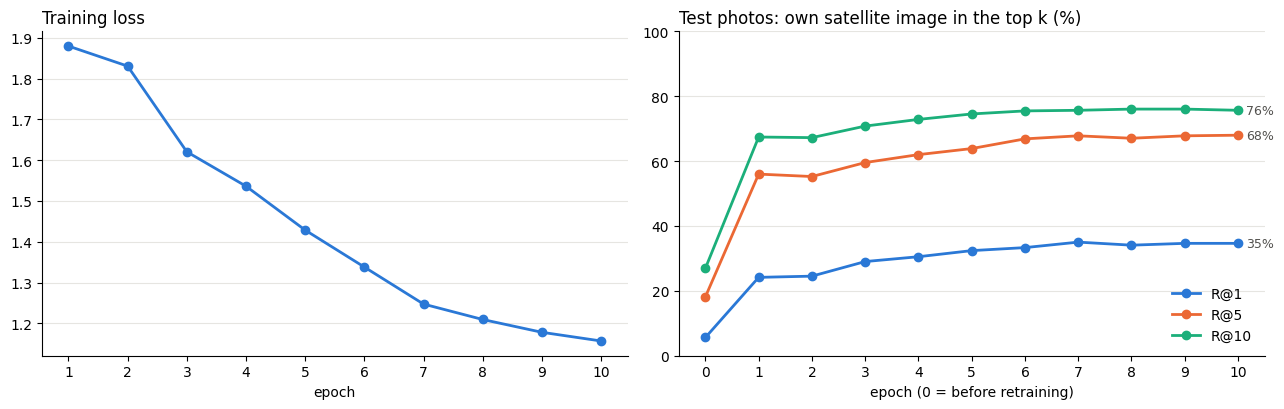

Best epoch: 7
                 photos  R@1 before  R@1 after  R@5 before  R@5 after  R@10 before  R@10 after
all photos          534        5.62      35.02       18.16      67.79        26.97       75.66
minor damage        328        5.49      32.01       21.04      67.38        31.10       75.61
moderate damage     142        7.75      38.73       16.20      65.49        23.24       73.94
severe damage        64        1.56      42.19        7.81      75.00        14.06       79.69
left photos         267        7.12      31.46       18.73      64.04        26.22       73.03
right photos        267        4.12      38.58       17.60      71.54        27.72       78.28

Saved to /content/drive/MyDrive/cvdisaster_perspective/run1: weights_best.pth, training_curves.png, before_vs_after.csv


In [ ]:
hist = pd.DataFrame(history)
SERIES = {"R@1": "#2a78d6", "R@5": "#eb6834", "R@10": "#1baf7a"}   # fixed colour per measure

fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 4.2))
trained = hist[hist.epoch > 0]
a0.plot(trained.epoch, trained.loss, color="#2a78d6", lw=2, marker="o", ms=6)
a0.set_title("Training loss", loc="left"); a0.set_xlabel("epoch")
for name, colour in SERIES.items():
    a1.plot(hist.epoch, hist[name], color=colour, lw=2, marker="o", ms=6, label=name)
    a1.annotate(f"{hist[name].iloc[-1]:.0f}%", (hist.epoch.iloc[-1], hist[name].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#52514e")
a1.set_title("Test photos: own satellite image in the top k (%)", loc="left")
a1.set_xlabel("epoch (0 = before retraining)"); a1.set_ylim(0, 100); a1.legend(frameon=False, loc="lower right")
for ax in (a0, a1):
    ax.grid(axis="y", color="#e6e5e1", lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.set_xticks(trained.epoch if ax is a0 else hist.epoch)
plt.tight_layout()
plt.savefig(f"{RUN_DIR}/training_curves.png", dpi=150)
plt.show()

before = pd.read_csv(f"{RUN_DIR}/before_results.csv", index_col=0)
best = pd.read_csv(f"{RUN_DIR}/best_results.csv", index_col=0)
compare = pd.DataFrame({"photos": best["photos"],
                        "R@1 before": before["R@1"], "R@1 after": best["R@1"],
                        "R@5 before": before["R@5"], "R@5 after": best["R@5"],
                        "R@10 before": before["R@10"], "R@10 after": best["R@10"]})
print(f"Best epoch: {int(hist.loc[hist['R@1'].idxmax(), 'epoch'])}")
print(compare.to_string())
compare.to_csv(f"{RUN_DIR}/before_vs_after.csv")
print(f"\nSaved to {RUN_DIR}: weights_best.pth, training_curves.png, before_vs_after.csv")

## Step 9 – Set the verification threshold
Your pipeline accepts a photo if its similarity to its satellite image is at least a threshold. This step sets that threshold
from the held-out test photos, which the model never trained on:
* **genuine pairs**: each test photo with its own satellite image
* **mismatched pairs**: each test photo with every other test location's satellite image

The threshold is set so that only `FALSE_ACCEPT_RATE` of mismatched pairs would be accepted (5% by default).
It is saved as `verification_threshold.json` next to the model, and your test notebook (cell 14) reads it automatically.
This step can be run on its own after Steps 1–6 without retraining.

Test photos: 534 genuine pairs, 142044 mismatched pairs

Scoring method                            R@1  Threshold  Genuine accepted  Mismatched accepted
satellite image tested once             35.0%      0.335             77.7%                 5.0%
average over 4 satellite rotations      39.3%      0.325             79.2%                 5.0%
best of 4 satellite rotations           37.8%      0.365             78.7%                 5.0%

Best: average over 4 satellite rotations. Other false-accept levels for this method:
 Mismatched pairs accepted  Threshold   Genuine pairs accepted
                       1%       0.425                   54.5%
                       5%       0.325                   79.2%
                      10%       0.272                   88.0%
                      20%       0.209                   92.9%

Threshold 0.325 (average over 4 satellite rotations) was set on 534 held-out CVIAN test photos: at this level 5% of mismatched photo/satellite pairs are wrongly 

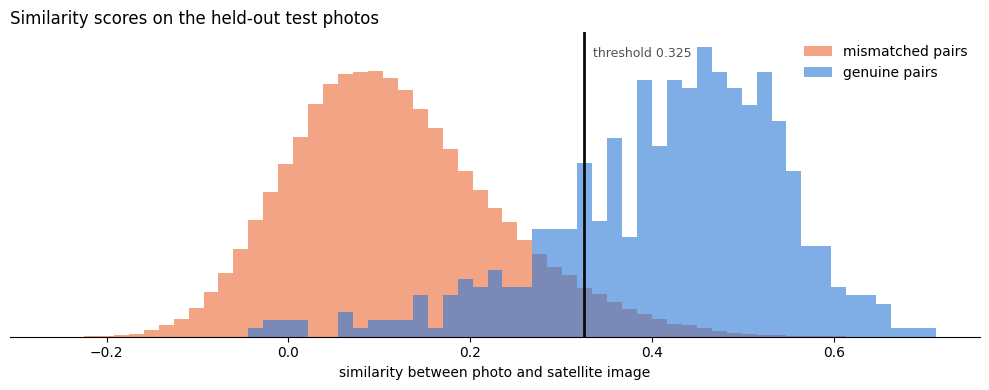

In [ ]:
FALSE_ACCEPT_RATE = 0.05     # share of mismatched photo/satellite pairs you are willing to accept by mistake

RUN_DIR = f"{OUT_ROOT}/{RUN_NAME}"
model.load_state_dict(torch.load(f"{RUN_DIR}/weights_best.pth", map_location="cpu"))
model = model.to(device)

# Score every test photo against every test satellite image, with the satellite image at 0, 90, 180 and 270 degrees
class RotatedList(ImageList):
    def __init__(self, paths, tf, k):
        super().__init__(paths, tf); self.k = k
    def __getitem__(self, i):
        return torch.rot90(super().__getitem__(i), self.k, dims=(1, 2))

@torch.no_grad()
def embed_rotated(paths, k, bs=64):
    model.eval()
    out = []
    for x in DataLoader(RotatedList(paths, test_tf((SAT_SIZE, SAT_SIZE)), k), batch_size=bs, num_workers=NUM_WORKERS):
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            f = model(x.to(device, non_blocking=True))
        out.append(F.normalize(f.float(), dim=-1))
    return torch.cat(out)

pt = photo_table(test_locs)
q = embed(pt.path, GROUND_SIZE)
sims = torch.stack([q @ embed_rotated(test_locs.sat, k).T for k in range(4)])   # 4 x photos x satellites
METHODS = {"single": sims[0], "mean4": sims.mean(0), "max4": sims.max(0).values}
METHOD_NAMES = {"single": "satellite image tested once", "mean4": "average over 4 satellite rotations",
                "max4": "best of 4 satellite rotations"}

own = torch.tensor(pt["loc"].to_numpy(), device=q.device)
rows_idx = torch.arange(len(pt), device=q.device)
mask = torch.ones_like(sims[0], dtype=torch.bool); mask[rows_idx, own] = False

def evaluate_method(sim):
    genuine = sim[rows_idx, own].cpu().numpy()
    mismatched = sim[mask].cpu().numpy()
    thr = float(np.quantile(mismatched, 1 - FALSE_ACCEPT_RATE))
    r1 = float(((sim > sim[rows_idx, own][:, None]).sum(1) == 0).float().mean())
    return {"genuine": genuine, "mismatched": mismatched, "threshold": thr,
            "tar": float(np.mean(genuine >= thr)), "far": float(np.mean(mismatched >= thr)), "r1": r1}

results = {m: evaluate_method(s) for m, s in METHODS.items()}
print(f"Test photos: {len(pt)} genuine pairs, {int(mask.sum())} mismatched pairs\n")
print(f"{'Scoring method':<38}{'R@1':>7}{'Threshold':>11}{'Genuine accepted':>18}{'Mismatched accepted':>21}")
for m, r in results.items():
    print(f"{METHOD_NAMES[m]:<38}{r['r1']:>7.1%}{r['threshold']:>11.3f}{r['tar']:>18.1%}{r['far']:>21.1%}")

METHOD = max(results, key=lambda m: results[m]["tar"])
r = results[METHOD]
genuine, mismatched, threshold, tar, far = r["genuine"], r["mismatched"], r["threshold"], r["tar"], r["far"]
print(f"\nBest: {METHOD_NAMES[METHOD]}. Other false-accept levels for this method:")
print(f"{'Mismatched pairs accepted':>26}{'Threshold':>11}{'Genuine pairs accepted':>25}")
for f_ in (0.01, 0.05, 0.10, 0.20):
    thr = float(np.quantile(mismatched, 1 - f_))
    print(f"{f_:>25.0%} {thr:>11.3f}{np.mean(genuine >= thr):>24.1%}")

explanation = (f"Threshold {threshold:.3f} ({METHOD_NAMES[METHOD]}) was set on {len(genuine)} held-out CVIAN test photos: "
               f"at this level {far:.0%} of mismatched photo/satellite pairs are wrongly accepted and {tar:.0%} of genuine pairs are accepted.")
json.dump({"threshold": threshold, "satellite_rotations": METHOD, "false_accept_rate": far, "genuine_accept_rate": tar,
           "test_photos": int(len(genuine)), "explanation": explanation},
          open(f"{RUN_DIR}/verification_threshold.json", "w"), indent=2)
print("\n" + explanation)
print(f"Saved to {RUN_DIR}/verification_threshold.json")

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(min(genuine.min(), mismatched.min()), max(genuine.max(), mismatched.max()), 60)
ax.hist(mismatched, bins=bins, density=True, color="#eb6834", alpha=0.6, label="mismatched pairs")
ax.hist(genuine, bins=bins, density=True, color="#2a78d6", alpha=0.6, label="genuine pairs")
ax.axvline(threshold, color="#0b0b0b", lw=2)
ax.annotate(f"threshold {threshold:.3f}", (threshold, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color="#52514e")
ax.set_title("Similarity scores on the held-out test photos", loc="left")
ax.set_xlabel("similarity between photo and satellite image"); ax.set_yticks([])
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/verification_threshold.png", dpi=150); plt.show()

## Step 10 – Test your own photos with the new model
In your test notebook (`Sample4Geo_CVIAN.ipynb`), cell 14 has a `PERSPECTIVE_RUN` setting.
Point it at this run's folder, for example `/content/drive/MyDrive/cvdisaster_perspective/run1`.
It then loads `weights_best.pth` and feeds your photos straight in, with no panorama padding and no heading sweep.
The new model's similarity scores sit on a different scale, so set the heatmap verdict thresholds (`MATCH_THRESHOLD`, `MIN_SPREAD`) again
using your real pairs and the false test.